# 03 - Spatial EDA by district

**Question:** can the 25 districts (gu) be ranked by PM2.5 exposure, or are the differences between stations partly a product of how each station is measured?

Each district has one urban monitoring station, so a district value is the value of its station. If a station moves or its instruments change, its level can change while the air of the district does not. This notebook checks that before comparing districts.

**Official station history:** table 19.1 of the [*2018 Seoul Air Quality Assessment Report*](https://news.seoul.go.kr/env/files/2021/01/60112177d83700.85894331.pdf) (2018년 서울 대기질 평가 보고서), Seoul Metropolitan Government, printed pages 97-98, transcribed to `data/reference/station_history.csv`. Its section on the heavy metals network gives the months of two relocations (Mapo-gu, August 2018; Songpa-gu, November 2018). It gives the year of the latest equipment replacement and of the latest relocation of each station, but not the month or which instrument was replaced. The coordinates of the dataset show only one location per station, so the data itself does not reveal a relocation.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from scipy.stats import fisher_exact

from seoul_air.data import load_station_history, load_stations
from seoul_air.report import save_key_figures
from seoul_air.station_levels import (agreed_shifts, change_around, detect_level_shifts, log_ratio,
                                      nearest_stations, neighbour_median, offset_from_city,
                                      offset_intervals, rest_of_city_mean, shuffle_blocks,
                                      station_outages, to_station_table)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly.parquet", columns=["datetime", "district", "pm25"])
stations = load_stations()
history = load_station_history()
daily["year"] = daily["date"].dt.year
daily["bad_or_worse"] = daily["pm25_grade"].isin(["Bad", "Very bad"]).where(daily["pm25"].notna())
pm25 = to_station_table(daily, "pm25")

## 2. District medians (descriptive, not a ranking)

The medians below describe what each station recorded. Sections 4 to 8 show why their order should not be read as a ranking of the air in each district.

In [3]:
by_district = daily.groupby("district").agg(
    pm25_median=("pm25", "median"),
    pm25_mean=("pm25", "mean"),
    pm25_bad_or_worse_days_pct=("bad_or_worse", lambda s: s.mean() * 100),
    no2_median=("no2", "median"),
    valid_pm25_days=("pm25", "count"),
).sort_values("pm25_median", ascending=False)
gap = by_district["pm25_median"].max() - by_district["pm25_median"].min()
print(f"Gap between the highest and lowest district median: {gap:.1f} ug/m3")
by_district.round(3)

Gap between the highest and lowest district median: 4.7 ug/m3


,pm25_median,pm25_mean,pm25_bad_or_worse_days_pct,no2_median,valid_pm25_days
district,,,,,
Gwanak-gu,23.320,26.994,23.161,0.028,1006
Mapo-gu,23.022,26.829,22.200,0.024,1018
Yeongdeungpo-gu,22.271,26.625,21.078,0.028,1058
Yangcheon-gu,21.864,25.770,20.822,0.029,1071
Nowon-gu,21.125,24.301,17.383,0.024,1070
Geumcheon-gu,21.064,24.487,16.948,0.029,1068
Eunpyeong-gu,20.979,24.467,17.308,0.023,1040
Gangdong-gu,20.958,24.419,17.167,0.028,1066
Seongdong-gu,20.956,24.671,18.491,0.027,1060


In [4]:
yearly = daily.pivot_table(index="district", columns="year", values="pm25", aggfunc="median")
ranks = yearly.rank(ascending=False).astype(int)
print("Spearman correlation of district medians between years:")
print(yearly.corr(method="spearman").round(2).to_string())
ranks.sort_values(ranks.columns[-1]).head(10)

Spearman correlation of district medians between years:
year  2017  2018  2019
year                  
2017  1.00  0.14  0.12
2018  0.14  1.00  0.22
2019  0.12  0.22  1.00


year,2017,2018,2019
district,,,
Yeongdeungpo-gu,23,1,1
Gwanak-gu,3,2,2
Mapo-gu,2,4,3
Gangdong-gu,19,7,4
Nowon-gu,5,17,5
Dongjak-gu,8,23,6
Yangcheon-gu,1,15,7
Gwangjin-gu,18,18,8
Gangseo-gu,16,14,9


**Interpretation.** Gwanak-gu (23.3 ug/m3), Mapo-gu (23.0) and Yeongdeungpo-gu (22.3) record the highest median daily PM2.5 and Gangbuk-gu the lowest (18.6), a gap of 4.7 ug/m3. This order is not stable: the Spearman correlation of district medians between years is only 0.12 to 0.22, and Yeongdeungpo-gu goes from 23rd in 2017 to 1st in 2018 and 2019. The medians also rest on different days: Gwanak-gu has the fewest valid days (1,006), with most of September and October 2019 missing. The next sections look for the reason before any comparison.

## 3. Between-district vs day-to-day variation

In [5]:
corr = pm25.corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f"Pairwise correlation of daily PM2.5 between districts: min {off_diag.min():.2f}, median {off_diag.median():.2f}")

v = daily.dropna(subset=["pm25"])
v = v.assign(month=v["date"].dt.month, year_month=v["date"].dt.to_period("M"))
total_var = v["pm25"].var()


def variance_share(group):
    return 1 - (v["pm25"] - v.groupby(group)["pm25"].transform("mean")).var() / total_var


# These groups are nested or overlapping, so the shares do not add up to 100%
shares = {
    "Date (each single day)": "date",
    "Month of each specific year": "year_month",
    "Calendar month (season)": "month",
    "District": "district",
}
variance_pct = pd.Series({name: variance_share(group) * 100 for name, group in shares.items()})
variance_pct.round(1).to_frame("variance_share_%")

Pairwise correlation of daily PM2.5 between districts: min 0.90, median 0.95


,variance_share_%
Date (each single day),94.3
Month of each specific year,27.1
Calendar month (season),23.4
District,0.6


**Interpretation.** Daily PM2.5 moves together across Seoul: the correlation between any two districts is at least 0.90 (median 0.95). The 94.3% accounted for by the date is not seasonality: it includes every change from one day to the next. The calendar month accounts for 23.4% of the variance and the month of each specific year for 27.1%, so most of the variance comes from day-to-day changes within the same month, which the districts share. The district accounts for only 0.6%. Season therefore matters far more than district, but neither explains the largest part of the variation. The dataset has no weather variables, so it cannot show what lies behind those daily changes. Because PM2.5 behaves as a city-wide signal, the forecast in notebook 05 uses the city-wide mean as a feature.

## 4. Each station against the rest of the city

All stations share the same weather and the same regional air, so the **offset** (a station minus the mean of the other stations on the same day) removes those common changes. It also removes the bias of comparing stations measured on different days. If stations differed only by their location, each offset would stay roughly constant.

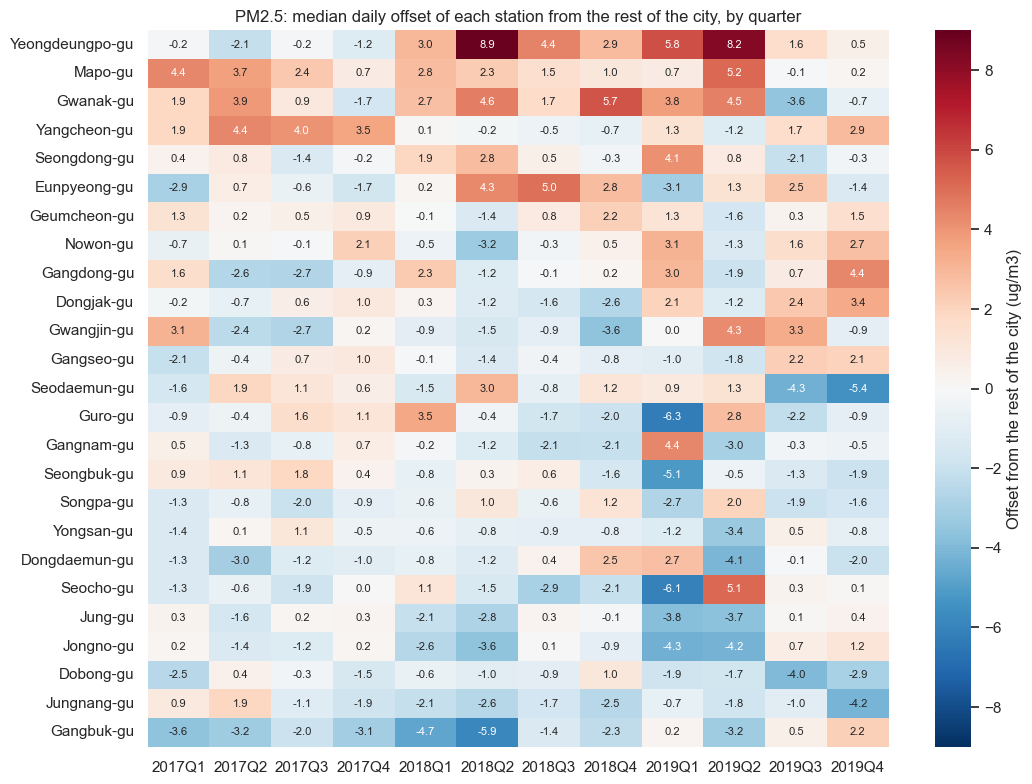

Range of each station's quarterly offset: median 6.4 ug/m3, largest 11.3 (Seocho-gu)
Stations whose quarterly offset changes sign: 25 of 25
Stations that do not: []


In [6]:
offset = offset_from_city(pm25)
weekly_offset = offset.resample("W").median()
quarterly = offset.resample("QS").median().T
quarterly.columns = pd.PeriodIndex(quarterly.columns, freq="Q").astype(str)
order = quarterly.mean(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(quarterly.loc[order], cmap="RdBu_r", center=0, vmin=-9, vmax=9, annot=True, fmt=".1f",
            annot_kws={"size": 8}, cbar_kws={"label": "Offset from the rest of the city (ug/m3)"}, ax=ax)
ax.set_title("PM2.5: median daily offset of each station from the rest of the city, by quarter")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_offset_heatmap.png", dpi=120)
plt.show()

swing = quarterly.max(axis=1) - quarterly.min(axis=1)
print(f"Range of each station's quarterly offset: median {swing.median():.1f} ug/m3, largest {swing.max():.1f} ({swing.idxmax()})")
changes_sign = (quarterly.max(axis=1) > 0) & (quarterly.min(axis=1) < 0)
print(f"Stations whose quarterly offset changes sign: {int(changes_sign.sum())} of {len(quarterly)}")
print("Stations that do not:", list(quarterly.index[~changes_sign]))

**Interpretation.** No station keeps a constant position. The offset of all 25 stations changes sign at some quarter, and the typical station moves over a range of 6.4 ug/m3 between its quarterly extremes (11.3 for Seocho-gu). That range is larger than the 4.7 ug/m3 that separates the highest and lowest district medians, so the movement of a single station over time can exceed the whole difference between districts.

## 5. Official changes and data outages

The official table gives only years. Long outages of a single station, when the rest of the network keeps reporting, can narrow down when a change happened: moving a station or replacing its instruments interrupts the readings. An outage is a run of at least 72 hours without PM2.5 at one station.

In [7]:
history.sort_values(["equipment_replaced", "district"], ascending=[False, True])

,district,installed,equipment_replaced,last_relocation,relocated_from
5,Dongdaemun-gu,1979,2019,2003,Sungin Girls' Middle School
22,Gangnam-gu,1978,2019,2012,Irwon-dong
20,Gwanak-gu,1979,2019,2001,Seoul National University ROTC building
6,Jungnang-gu,1984,2019,2009,Myeonmok drainage pump station
13,Mapo-gu,1997,2019,2018,Mapo Art Center
7,Seongbuk-gu,1978,2019,1988,Gireum 3-dong office
18,Yeongdeungpo-gu,1973,2019,2003,Mullae 2-dong office
9,Dobong-gu,1982,2018,2009,Banghak 1-dong office
11,Eunpyeong-gu,1995,2018,2012,Bulgwang 1-dong office
24,Gangdong-gu,1997,2018,<NA>,NaN


In [8]:
outages = station_outages(hourly, "pm25")
outages["year"] = outages["start"].dt.year
outages = outages.merge(history[["district", "equipment_replaced", "last_relocation"]], on="district")
outages["documented_that_year"] = (outages["year"].eq(outages["equipment_replaced"])
                                   | outages["year"].eq(outages["last_relocation"]).fillna(False)).astype(bool)
print(f"Outages of at least 72 hours: {len(outages)}, in {outages['district'].nunique()} stations")
print(f"In the same year as a documented change: {int(outages['documented_that_year'].sum())}")
outages.sort_values("start")[["district", "start", "end", "days", "equipment_replaced", "last_relocation", "documented_that_year"]]

Outages of at least 72 hours: 20, in 13 stations
In the same year as a documented change: 16


,district,start,end,days,equipment_replaced,last_relocation,documented_that_year
2,Gangnam-gu,2017-03-21 14:00:00,2017-03-27 12:00:00,6.0,2019,2012,False
4,Gangseo-gu,2017-12-15 12:00:00,2017-12-31 23:00:00,16.5,2018,<NA>,False
16,Seodaemun-gu,2017-12-22 14:00:00,2018-01-13 23:00:00,22.4,2018,2018,False
15,Seocho-gu,2018-02-23 08:00:00,2018-03-05 23:00:00,10.7,2018,<NA>,True
5,Guro-gu,2018-02-23 09:00:00,2018-03-06 10:00:00,11.1,2018,2012,True
19,Yongsan-gu,2018-02-26 08:00:00,2018-03-12 23:00:00,14.7,2018,<NA>,True
9,Gwangjin-gu,2018-03-21 08:00:00,2018-03-27 11:00:00,6.2,2018,<NA>,True
11,Mapo-gu,2018-07-25 13:00:00,2018-07-30 11:00:00,5.0,2019,2018,True
12,Mapo-gu,2018-07-31 15:00:00,2018-08-04 12:00:00,3.9,2019,2018,True
17,Seodaemun-gu,2018-10-19 15:00:00,2018-11-09 08:00:00,20.8,2018,2018,True


In [9]:
changed = history["equipment_replaced"].isin([2018, 2019]) | history["last_relocation"].isin([2018, 2019])
had_outage = history["district"].isin(outages.loc[outages["year"].isin([2018, 2019]), "district"])
table = pd.crosstab(changed.map({True: "Change documented in 2018-2019", False: "No change documented in 2018-2019"}),
                    had_outage.map({True: "Outage in 2018-2019", False: "No outage in 2018-2019"}))
print(f"Fisher exact test, p = {fisher_exact(table)[1]:.4f}")
table.rename_axis(index=None, columns=None)

Fisher exact test, p = 0.0052


,No outage in 2018-2019,Outage in 2018-2019
Change documented in 2018-2019,6,12
No change documented in 2018-2019,7,0


**Interpretation.** Long outages and documented changes go together. All 12 stations with an outage in 2018-2019 had a relocation or an equipment replacement documented for those years, and none of the 7 stations without a documented change had an outage (Fisher exact test, p = 0.0052). 16 of the 20 outages fall in the year of a documented change, and the official report attributes missing periods to causes that include equipment replacement. The dates also fit: the outages of Mapo-gu end on 2018-08-04 and the report dates its relocation to August 2018; the outage of Songpa-gu ends on 2018-11-12 and its relocation is dated November 2018. The outage of Seodaemun-gu, which ends on 2018-11-09, suggests when its relocation happened, and those of Gwanak-gu, Mapo-gu, Jungnang-gu and Dongdaemun-gu in September and October 2019 suggest when their equipment was replaced, but no source gives these two dates. This is an association: the report does not explain each outage, and 6 stations with a documented change have no outage, among them Yeongdeungpo-gu.

## 6. Level shifts

A level shift is a lasting change of the offset. Detection works on the weekly median of `log(station / reference)`, so that a shift is comparable between a clean summer and a polluted winter, and uses circular binary segmentation, which also finds a change that later reverses. A stretch must differ from the rest of the series by at least 10%, last at least 20 weeks and pass a test against block-shuffled series ($p \le 0.01$).

One test alone flags too many stations, because offsets wander on their own. A shift is therefore accepted only if it appears against **two references**, the rest of the city and the 5 nearest stations, with the same sign and within 8 weeks. The nearest stations share local conditions, so a change they also show is not specific to the station.

In [10]:
near = nearest_stations(stations, k=5)


def weekly_ratios(pollutant):
    table = to_station_table(daily, pollutant)
    city_ratio = log_ratio(table, rest_of_city_mean(table)).resample("W").median()
    near_ratio = log_ratio(table, neighbour_median(table, near)).resample("W").median()
    return city_ratio, near_ratio


def find_agreed(city_ratio, near_ratio, **options):
    found = []
    for district in city_ratio.columns:
        by_city = detect_level_shifts(city_ratio[district], **options)
        by_near = detect_level_shifts(near_ratio[district], **options)
        agreed = agreed_shifts(by_city, by_near)
        if not agreed.empty:
            found.append(agreed.assign(district=district))
    return pd.concat(found, ignore_index=True) if found else pd.DataFrame()


ratios = {p: weekly_ratios(p) for p in config.POLLUTANTS}
shifts = pd.concat([find_agreed(*ratios[p]).assign(pollutant=p) for p in config.POLLUTANTS], ignore_index=True)
shifts["change_%"] = np.expm1(shifts["jump"]) * 100
shifts = shifts[["district", "pollutant", "date", "date_near", "change_%", "p_value"]]
print("Agreed shifts per pollutant:", shifts["pollutant"].value_counts().to_dict())
pm_shifts = shifts[shifts["pollutant"] == "pm25"].sort_values(["district", "date"]).reset_index(drop=True)
pm_shifts.round({"change_%": 1, "p_value": 4})

Agreed shifts per pollutant: {'so2': 18, 'pm10': 14, 'o3': 12, 'no2': 11, 'co': 9, 'pm25': 9}


,district,pollutant,date,date_near,change_%,p_value
0,Dobong-gu,pm25,2019-07-07,2019-07-07,-23.5,0.010
1,Dongdaemun-gu,pm25,2019-03-10,2019-03-24,-17.0,0.006
2,Gwangjin-gu,pm25,2019-03-24,2019-04-21,34.3,0.006
3,Gwangjin-gu,pm25,2019-11-17,2019-11-17,-25.6,0.006
4,Seodaemun-gu,pm25,2019-07-28,2019-07-28,-35.9,0.002
5,Yangcheon-gu,pm25,2017-12-10,2017-12-17,-17.3,0.004
6,Yangcheon-gu,pm25,2019-07-07,2019-07-28,20.9,0.004
7,Yeongdeungpo-gu,pm25,2017-12-31,2017-12-10,29.7,0.008
8,Yeongdeungpo-gu,pm25,2019-10-27,2019-09-29,-22.9,0.008


In [11]:
# False-alarm check: the same rule on PM2.5 series whose weeks are shuffled in blocks.
# Shuffling removes real shifts, so anything found here is a false alarm.
rng = np.random.default_rng(0)
city_ratio, near_ratio = ratios["pm25"]
false_alarms = []
for repeat in range(20):
    positions = shuffle_blocks(len(city_ratio), block=8, rng=rng)
    shuffled_city = city_ratio.iloc[positions].set_axis(city_ratio.index)
    shuffled_near = near_ratio.iloc[positions].set_axis(near_ratio.index)
    false_alarms.append(len(find_agreed(shuffled_city, shuffled_near, n_perm=199, seed=repeat)))
false_alarms = np.array(false_alarms)
print(f"Agreed PM2.5 shifts in the real data: {len(pm_shifts)}")
print(f"Agreed PM2.5 shifts in 20 shuffled datasets: mean {false_alarms.mean():.1f}, "
      f"median {np.median(false_alarms):.0f}, max {false_alarms.max()}")
print(f"Shuffled datasets with at least as many shifts as the real data: {int((false_alarms >= len(pm_shifts)).sum())} of 20")
pd.Series(false_alarms).value_counts().sort_index().rename_axis("shifts_found").to_frame("shuffled_datasets").T

Agreed PM2.5 shifts in the real data: 9
Agreed PM2.5 shifts in 20 shuffled datasets: mean 1.2, median 0, max 11
Shuffled datasets with at least as many shifts as the real data: 1 of 20


shifts_found,0,2,3,4,5,11
shuffled_datasets,15,1,1,1,1,1


**Interpretation.** The rule accepts 9 PM2.5 level shifts in 6 stations: Dobong-gu, Dongdaemun-gu, Gwangjin-gu, Seodaemun-gu, Yangcheon-gu and Yeongdeungpo-gu. The false-alarm check gives no shifts in 15 of the 20 shuffled datasets (mean 1.2), but 1 of the 20 reaches 11. The total of 9 is therefore high for chance, although not decisively so, and any single shift could be a false alarm. Only 2 of the 9 fall in the documented year of an equipment replacement (Dongdaemun-gu and the second one of Yeongdeungpo-gu), and none in the year of a relocation: Seodaemun-gu, relocated in 2018, shifts by -35.9% in July 2019. Three shifts fall in July 2019 at different stations (Dobong-gu, Seodaemun-gu and Yangcheon-gu). For most of the 9, then, the available records offer no explanation; a shift may also reflect a real local change around the station.

## 7. Do documented changes move the offset?

For each outage in the year of a documented change, the table compares the 13 weeks after the outage with the 13 weeks before it, for all six pollutants. The last row shows how large such a change is at any station on any date: the 95th percentile of the absolute change over all station-weeks. Only a value beyond that is unusual.

In [12]:
events = outages[outages["documented_that_year"]].sort_values("end").groupby(["district", "year"]).tail(1)
rows = []
for event in events.itertuples():
    row = {"district": event.district, "after_outage_ending": event.end.date()}
    for pollutant in config.POLLUTANTS:
        change = change_around(ratios[pollutant][0][event.district], event.end)
        row[pollutant] = np.expm1(change) * 100
    rows.append(row)
study = pd.DataFrame(rows).set_index(["district", "after_outage_ending"]).sort_index(level=1)

typical = {}
for pollutant in config.POLLUTANTS:
    weekly = ratios[pollutant][0]
    changes = [abs(change_around(weekly[d], date)) for d in weekly.columns for date in weekly.index[13:-13]]
    typical[pollutant] = np.expm1(np.nanpercentile(changes, 95)) * 100
print("95th percentile of the absolute change, in %:", {k: round(float(v), 1) for k, v in typical.items()})
unusual = study.abs() > pd.Series(typical)
print(f"Changes beyond that level: {int(unusual.to_numpy().sum())} of {unusual.size} (chance alone gives about 5%)")
print("By pollutant:", {k: int(v) for k, v in unusual.sum().items()}, "of", len(unusual), "events")
study.round(1)

95th percentile of the absolute change, in %: {'so2': 41.6, 'no2': 24.4, 'co': 33.4, 'o3': 25.4, 'pm10': 21.5, 'pm25': 27.5}
Changes beyond that level: 14 of 72 (chance alone gives about 5%)
By pollutant: {'so2': 2, 'no2': 5, 'co': 2, 'o3': 2, 'pm10': 2, 'pm25': 1} of 12 events


,,so2,no2,co,o3,pm10,pm25
district,after_outage_ending,,,,,,
Seocho-gu,2018-03-05,-33.8,7.3,-13.0,13.7,-1.8,-12.8
Guro-gu,2018-03-06,-25.1,25.6,-34.3,60.7,-1.8,-10.7
Yongsan-gu,2018-03-12,-9.9,10.9,42.0,11.1,-2.3,8.6
Gwangjin-gu,2018-03-27,9.2,-12.1,6.6,-11.1,4.2,-4.8
Mapo-gu,2018-08-04,-26.3,-7.7,-5.7,-5.6,-1.6,8.9
Seodaemun-gu,2018-11-09,63.0,17.5,20.8,-0.4,0.6,9.1
Songpa-gu,2018-11-12,2.4,34.4,-29.2,-24.3,11.9,9.0
Gangnam-gu,2019-09-06,-29.0,31.2,9.1,25.4,5.2,3.7
Gwanak-gu,2019-10-22,-10.2,-0.1,24.4,-10.6,16.2,41.9


**Interpretation.** Documented changes do not leave a common mark on PM2.5. Across the 12 events, 14 of the 72 changes exceed the 95th percentile of what any station shows on any date, more than the 5% expected by chance, but they are spread over the pollutants (5 for NO2) and only 1 is for PM2.5: Gwanak-gu, +41.9%. The relocations of Mapo-gu (8.9%), Seodaemun-gu (9.1%) and Songpa-gu (9.0%) stay well below the 27.5% that marks an unusual PM2.5 change. So some gas readings may respond to these changes, but relocations are not shown to bias PM2.5 by a measurable amount. The test has limits: PM2.5 offsets are noisy, so a real change of about 10% would go unnoticed; Seongdong-gu has no outage to date its relocation; pollutants of the same event are not independent; and the data ends about 10 weeks after the outages of 2019.

## 8. The case of Yeongdeungpo-gu

Yeongdeungpo-gu ranks 23rd in 2017 and 1st in 2018 and 2019. The chart follows its PM2.5 and PM10 against the two references. The official table records no relocation since 2003 and an equipment replacement in 2019, without a month.

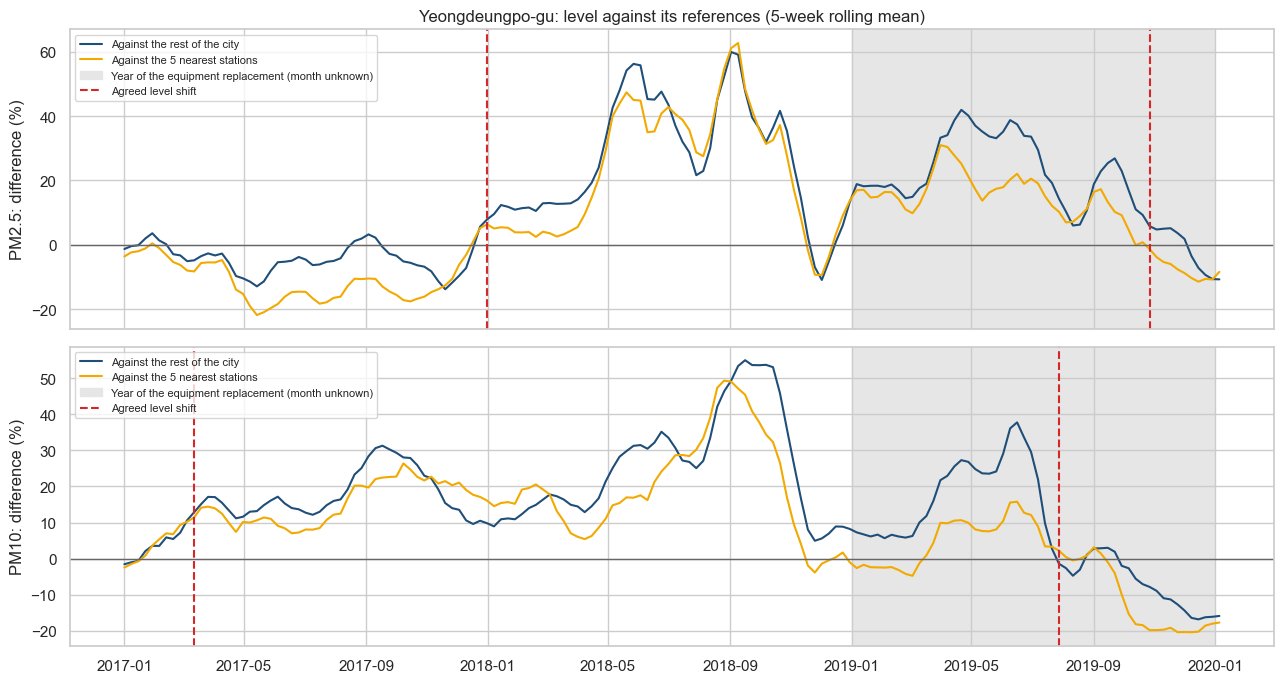

,district,pollutant,date,date_near,change_%,p_value
62,Yeongdeungpo-gu,pm10,2017-03-12,2017-02-12,26.5,0.002
16,Yeongdeungpo-gu,so2,2017-08-27,2017-08-27,42.0,0.002
71,Yeongdeungpo-gu,pm25,2017-12-31,2017-12-10,29.7,0.008
17,Yeongdeungpo-gu,so2,2018-12-16,2018-12-23,-29.6,0.002
34,Yeongdeungpo-gu,co,2019-01-13,2019-01-13,-30.5,0.002
63,Yeongdeungpo-gu,pm10,2019-07-28,2019-09-22,-20.9,0.002
72,Yeongdeungpo-gu,pm25,2019-10-27,2019-09-29,-22.9,0.008
35,Yeongdeungpo-gu,co,2019-12-15,2019-12-15,43.9,0.002


In [13]:
name = "Yeongdeungpo-gu"
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, pollutant, label in zip(axes, ["pm25", "pm10"], ["PM2.5", "PM10"]):
    city_ratio, near_ratio = ratios[pollutant]
    ax.plot(np.expm1(city_ratio[name].rolling(5, center=True, min_periods=3).mean()) * 100,
            color="#1f4e79", label="Against the rest of the city")
    ax.plot(np.expm1(near_ratio[name].rolling(5, center=True, min_periods=3).mean()) * 100,
            color="#f2a900", label="Against the 5 nearest stations")
    ax.axhline(0, color="0.4", lw=1)
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2019-12-31"), color="0.9", zorder=0,
               label="Year of the equipment replacement (month unknown)")
    for date in shifts[(shifts["district"] == name) & (shifts["pollutant"] == pollutant)]["date"]:
        ax.axvline(date, color="#d62728", ls="--", label="Agreed level shift")
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), fontsize=8, loc="upper left")
    ax.set_ylabel(f"{label}: difference (%)")
axes[0].set_title(f"{name}: level against its references (5-week rolling mean)")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_yeongdeungpo_case.png", dpi=120)
plt.show()
shifts[shifts["district"] == name].sort_values("date").round({"change_%": 1, "p_value": 4})

In [14]:
by_quarter = pd.DataFrame({
    p: np.expm1(ratios[p][0].loc[:"2019-12-31", name].resample("QS").mean()) * 100 for p in config.POLLUTANTS
})
by_quarter.index = by_quarter.index.to_period("Q").astype(str)
together = ratios["pm25"][0].corrwith(ratios["pm10"][0]).sort_values(ascending=False)
print("Correlation of the weekly PM2.5 and PM10 offsets:")
print(f"{name}: {together[name]:.2f}, position {list(together.index).index(name) + 1} of {len(together)}; "
      f"median of all stations: {together.median():.2f}")
print("Difference from the rest of the city by quarter (%):")
by_quarter.T.round(1)

Correlation of the weekly PM2.5 and PM10 offsets:
Yeongdeungpo-gu: 0.55, position 12 of 25; median of all stations: 0.54
Difference from the rest of the city by quarter (%):


date,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1,2018Q2,2018Q3,2018Q4,2019Q1,2019Q2,2019Q3,2019Q4
so2,-4.2,3.2,-11.6,25.7,16.8,22.8,25.0,9.7,-7.3,-17.1,-24.5,-21.5
no2,-21.6,14.0,18.1,-4.9,-1.9,8.3,5.4,-20.3,4.3,5.4,42.2,5.0
co,29.8,42.9,30.2,21.4,6.5,20.2,21.7,16.5,-8.6,-16.9,-12.5,-10.9
o3,-18.6,1.8,15.6,3.9,-22.0,-11.6,-0.9,6.1,-10.9,-18.3,-4.0,-4.8
pm10,5.8,14.2,20.9,18.1,14.0,24.4,39.9,20.5,7.8,29.6,1.5,-11.8
pm25,-1.7,-7.2,-2.0,-6.0,12.0,37.2,38.8,14.3,17.7,37.4,17.8,2.0


**Interpretation.** **What the data shows:** the excess of Yeongdeungpo-gu is not a single step. Its PM2.5 is 1.7% to 7.2% below the rest of the city in every quarter of 2017, 37.2% and 38.8% above it in the second and third quarters of 2018, 14.3% and 17.7% above around the end of that year, 37.4% above in the second quarter of 2019 and only 2.0% above in the last one. The two agreed shifts (+29.7% around December 2017 and -22.9% in autumn 2019) mark the start and the end of that period, which explains its jump from 23rd to 1st place. PM10 has its highest values in the same period (39.9% in the third quarter of 2018 and 29.6% in the second of 2019), although the link between its PM2.5 and PM10 offsets is not unusual: 12th of 25 stations. **What fits an instrument effect:** the official table records no relocation since 2003 and an equipment replacement in 2019; CO, PM10 and PM2.5 all shift during that year; and no other pollutant has an agreed shift within 8 weeks of the rise. **What does not fit:** the excess peaks in the same quarter of two years instead of staying constant, and in the second peak the gases go the other way (SO2 -17.1% and CO -16.9% in the second quarter of 2019, after +22.8% and +20.2% a year earlier), which leaves a real local source of particles near the station as an open alternative. **What cannot be confirmed:** the table gives neither the month nor the instrument replaced, the station has no outage of 72 hours or more, and no record explains the rise. The cause is unknown, and only the operator's maintenance records could settle it. The excess may be instrumental or real; in either case it should not be read as a stable feature of the air of the district.

## 9. A comparison that does not overstate the differences

Instead of a ranking, each station gets a category, using its weekly offset from the rest of the city:

- **Not comparable:** relocated in 2017-2019 or with an agreed PM2.5 level shift, so a single level would mix different conditions.
- **Above / Below the rest of the city:** the 95% interval of the offset excludes zero and the offset has the same sign in all three years.
- **No consistent difference:** everything else, either because the interval includes zero or because the sign changes between years.

The intervals resample blocks of 4 weeks and keep all stations of a week together. An equipment replacement alone does not make a station not comparable: the table gives no month or instrument, and most stations had one in these years.

In [15]:
comparison = offset_intervals(weekly_offset, n_boot=2000, block=4)
# Yearly means come from daily values: the last week of 2019 is labelled January 2020
by_year = offset.groupby(offset.index.year).mean().T
assert list(by_year.columns) == [2017, 2018, 2019]
same_sign = (by_year > 0).all(axis=1) | (by_year < 0).all(axis=1)
relocated = set(history.loc[history["last_relocation"].between(2017, 2019), "district"])
shifted = set(pm_shifts["district"])


def category(row):
    if row.name in relocated or row.name in shifted:
        return "Not comparable"
    if row["offset_low"] > 0 and same_sign[row.name]:
        return "Above the rest of the city"
    if row["offset_high"] < 0 and same_sign[row.name]:
        return "Below the rest of the city"
    return "No consistent difference"


comparison["category"] = comparison.apply(category, axis=1)
comparison["reason"] = [
    "Relocated" if d in relocated and d not in shifted else
    "Level shift" if d in shifted and d not in relocated else
    "Relocated and level shift" if d in shifted else "" for d in comparison.index]
comparison = comparison.sort_values("offset", ascending=False)
comparison.to_csv(config.METRICS / "03_station_comparison.csv")
print(comparison["category"].value_counts().to_string())
print(f"\nMedian width of the 95% rank interval: {(comparison['rank_high'] - comparison['rank_low']).median():.0f} places of 25")
comparison.round(2)

category
No consistent difference      11
Not comparable                 9
Below the rest of the city     4
Above the rest of the city     1

Median width of the 95% rank interval: 10 places of 25


,offset,offset_low,offset_high,rank_low,rank_high,category,reason
district,,,,,,,
Yeongdeungpo-gu,2.49,1.49,3.75,1.0,4.0,Not comparable,Level shift
Gwanak-gu,2.37,1.43,3.40,1.0,4.0,Above the rest of the city,
Mapo-gu,2.28,1.45,3.13,1.0,4.0,Not comparable,Relocated
Yangcheon-gu,1.49,0.79,2.26,1.0,6.0,Not comparable,Level shift
Seongdong-gu,0.68,-0.01,1.42,4.0,12.0,Not comparable,Relocated
Nowon-gu,0.42,-0.27,0.94,5.0,14.0,No consistent difference,
Gangdong-gu,0.42,-0.41,1.24,5.0,16.0,No consistent difference,
Geumcheon-gu,0.37,-0.04,0.87,5.0,13.0,No consistent difference,
Dongjak-gu,0.34,-0.35,0.92,5.0,15.0,No consistent difference,


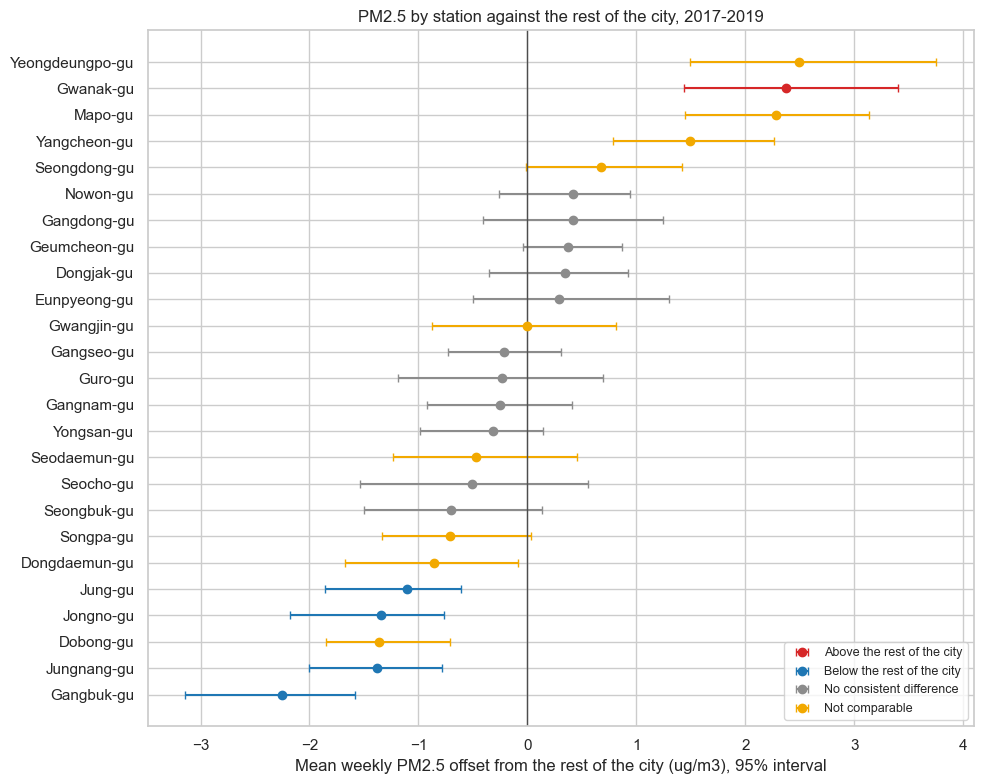

In [16]:
colors = {"Above the rest of the city": "#d62728", "Below the rest of the city": "#1f77b4",
          "No consistent difference": "0.55", "Not comparable": "#f2a900"}
fig, ax = plt.subplots(figsize=(10, 8))
c = comparison.iloc[::-1]
positions = np.arange(len(c))
for label, color in colors.items():
    mask = (c["category"] == label).to_numpy()
    ax.errorbar(c["offset"][mask].to_numpy(), positions[mask], fmt="o", color=color, capsize=3, label=label,
                xerr=[(c["offset"] - c["offset_low"])[mask].to_numpy(),
                      (c["offset_high"] - c["offset"])[mask].to_numpy()])
ax.axvline(0, color="0.3", lw=1)
ax.set_yticks(positions)
ax.set_yticklabels(c.index)
ax.set_xlabel("Mean weekly PM2.5 offset from the rest of the city (ug/m3), 95% interval")
ax.set_title("PM2.5 by station against the rest of the city, 2017-2019")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(config.FIGURES / "03_station_offsets.png", dpi=120)
plt.show()

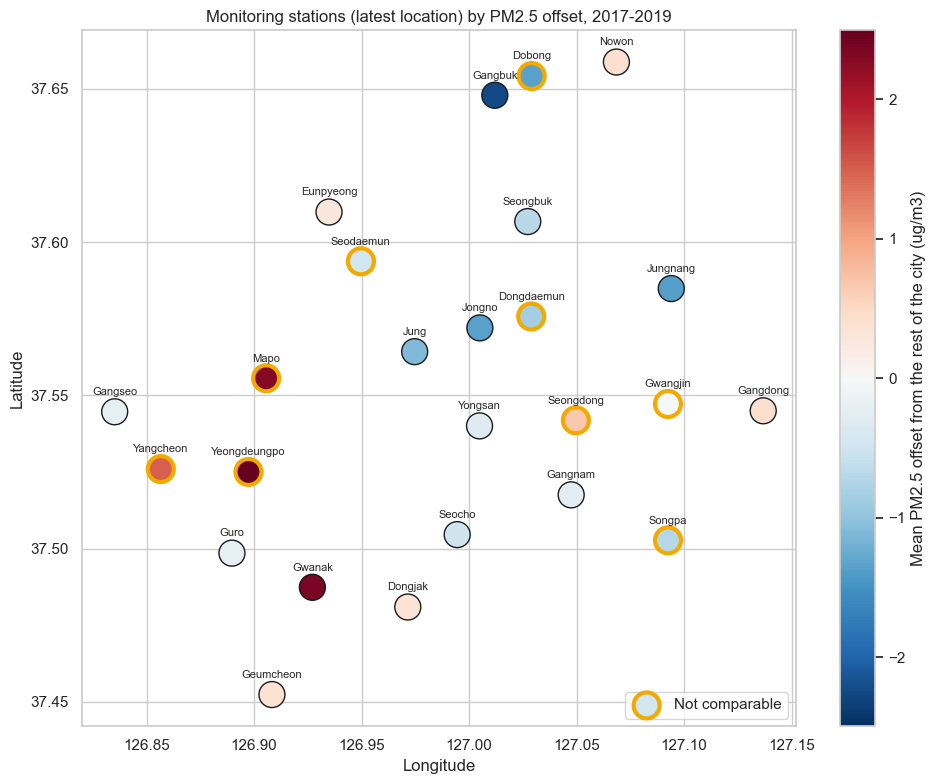

In [17]:
m = stations.merge(comparison, left_on="district", right_index=True)
fig, ax = plt.subplots(figsize=(10, 8))
limit = m["offset"].abs().max()
regular = m[m["category"] != "Not comparable"]
flagged = m[m["category"] == "Not comparable"]
sc = ax.scatter(regular["longitude"], regular["latitude"], c=regular["offset"], s=350, cmap="RdBu_r",
                vmin=-limit, vmax=limit, edgecolor="k")
ax.scatter(flagged["longitude"], flagged["latitude"], c=flagged["offset"], s=350, cmap="RdBu_r",
           vmin=-limit, vmax=limit, edgecolor="#f2a900", linewidth=3, label="Not comparable")
for _, r in m.iterrows():
    ax.annotate(r["district"].replace("-gu", ""), (r["longitude"], r["latitude"]),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8)
fig.colorbar(sc, ax=ax, label="Mean PM2.5 offset from the rest of the city (ug/m3)")
ax.set_title("Monitoring stations (latest location) by PM2.5 offset, 2017-2019")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_station_map.png", dpi=120)
plt.show()

**Interpretation.** Comparing each station with the others on the same days changes the picture. **9 stations are not comparable**, among them Yeongdeungpo-gu and Mapo-gu, two of the three highest medians. **11 show no consistent difference.** Only **5 keep a difference** over the three years: Gwanak-gu above the rest (+2.37 ug/m3), and Gangbuk-gu (-2.25), Jungnang-gu (-1.38), Jongno-gu (-1.35) and Jung-gu (-1.11) below. The median 95% interval of a rank spans 10 places of 25, so a position in a ranking says little. Even these 5 are tentative: Gwanak-gu had its equipment replaced in 2019, has a 34.5-day outage that year and shows the one unusual PM2.5 change after it. They describe one station each, not the air of a whole district, and an equipment replacement alone does not exclude a station. **Conclusion: this dataset does not support a ranking of districts by PM2.5.** Instrument effects are possible but unconfirmed; confirming them requires month-level maintenance records from the operator, the Seoul Research Institute of Public Health and Environment.

## 10. Key figures

In [18]:
between_years = yearly.corr(method="spearman").where(~np.eye(len(yearly.columns), dtype=bool)).stack()
save_key_figures("03", {
    "variance_share_pct": variance_pct.to_dict(),
    "min_pairwise_correlation": off_diag.min(),
    "spearman_between_years": [between_years.min(), between_years.max()],
    "median_gap_between_district_medians": gap,
    "median_quarterly_offset_range": swing.median(),
    "relocated_2017_2019": len(relocated),
    "categories": comparison["category"].value_counts().to_dict(),
})
print((config.METRICS / "03_key_figures.json").read_text())

{
  "categories": {
    "Above the rest of the city": 1,
    "Below the rest of the city": 4,
    "No consistent difference": 11,
    "Not comparable": 9
  },
  "median_gap_between_district_medians": 4.736413043478262,
  "median_quarterly_offset_range": 6.361059155216761,
  "min_pairwise_correlation": 0.9003660743013423,
  "relocated_2017_2019": 4,
  "spearman_between_years": [
    0.11542901115813775,
    0.21512411404597878
  ],
  "variance_share_pct": {
    "Calendar month (season)": 23.38996909246798,
    "Date (each single day)": 94.28442060027871,
    "District": 0.6219841833263628,
    "Month of each specific year": 27.110958018850617
  }
}

